# Week 2 – Feature Engineering & Data Preprocessing for Machine Learning
## Loan Prediction Dataset (will a loan application be approved?)

---
# Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')          # one consistent chart style
COLOUR = '#1f6f8b'

#folders (relative paths, so the notebook runs on any computer)
DATA_FOLDER = 'Original_Data'             # train_dataset.csv and test_dataset.csv live here
for folder in ['Cleaned_Data', 'ML_Ready_Data', 'Visualizations']:
    os.makedirs(folder, exist_ok=True)

def save_chart(filename):
    """Tidy the layout, save the chart into the Visualizations folder, then show it."""
    plt.tight_layout()
    plt.savefig(os.path.join('Visualizations', filename), dpi=150, bbox_inches='tight')
    plt.show()

preprocessing_log = []                    # every preprocessing step is recorded here (used in Part 5)
def log_step(part, step, what_was_done, why):
    preprocessing_log.append({'part': part, 'step': step, 'what_was_done': what_was_done, 'why': why})

---
# Part 2 – Data Inspection

In [2]:
train_df = pd.read_csv(os.path.join(DATA_FOLDER, 'train_dataset.csv'))
test_df = pd.read_csv(os.path.join(DATA_FOLDER, 'test_dataset.csv'))

print('Train set:', train_df.shape, '| Test set:', test_df.shape)
print('Columns in train but not in test:', set(train_df.columns) - set(test_df.columns))

Train set: (614, 13) | Test set: (367, 12)
Columns in train but not in test: {'Loan_Status'}


The test set has **no `Loan_Status` column** (the answers are kept back for the competition). So the test set can be *prepared* in exactly the same way as the training set, but it cannot be used to measure accuracy.

### Inspect the training set
`explore_df` is my function from week 1 submission, extended to cover everything the brief asks for: first 10 rows, structure, rows and columns, data types, missing values, **duplicate records** and **summary statistics**.

In [3]:
def explore_df(df, name='dataset'):
    print(f'===== {name} =====')
    print('1. Shape (rows, columns):', df.shape)
    print('\n2. First 10 rows:')
    display(df.head(10))
    print('\n3. Columns:', list(df.columns))
    print('\n4. Data types:')
    print(df.dtypes)
    print('\n5. Missing values per column:')
    print(df.isna().sum())
    print('\n6. Duplicate rows:', df.duplicated().sum())
    print('\n7. Summary statistics (numeric columns):')
    display(df.describe().round(2))
    print('\n8. Summary statistics (text columns):')
    display(df.describe(exclude='number'))

explore_df(train_df, 'TRAIN SET')

===== TRAIN SET =====
1. Shape (rows, columns): (614, 13)

2. First 10 rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N



3. Columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

4. Data types:
Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object

5. Missing values per column:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

6. Duplicate rows: 0



,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.00,614.00,592.00,600.00,564.00
mean,5403.46,1621.25,146.41,342.00,0.84
std,6109.04,2926.25,85.59,65.12,0.36
min,150.00,0.00,9.00,12.00,0.00
25%,2877.50,0.00,100.00,360.00,1.00
50%,3812.50,1188.50,128.00,360.00,1.00
75%,5795.00,2297.25,168.00,360.00,1.00
max,81000.00,41667.00,700.00,480.00,1.00



8. Summary statistics (text columns):


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


In [4]:
# a quick look at the test set (same checks, shorter output)
print('Test set shape:', test_df.shape)
print('Missing values per column:')
print(test_df.isna().sum()[test_df.isna().sum() > 0])
print('Duplicate rows:', test_df.duplicated().sum())

Test set shape: (367, 12)
Missing values per column:
Gender              11
Dependents          10
Self_Employed       23
LoanAmount           5
Loan_Amount_Term     6
Credit_History      29
dtype: int64
Duplicate rows: 0


### What the inspection shows
* **614 training rows, 13 columns** (12 features + the target); the test set has 367 rows and 12 columns.
* **Missing values** in 7 columns (largest: `Credit_History` 50, `Self_Employed` 32, `LoanAmount` 22). The test set has gaps in the same columns.
* **No duplicate rows** and no repeated `Loan_ID`.
* **Data types:** `Dependents` is text because it contains the value `3+`; `Credit_History` is a decimal number but really means yes/no.
* **Skewed incomes:** the mean applicant income is far above the median, and the maximum (81,000) is many times the typical value, which points to outliers.

{'Y': 422, 'N': 192} -> {'Y': 68.7, 'N': 31.3} (%)


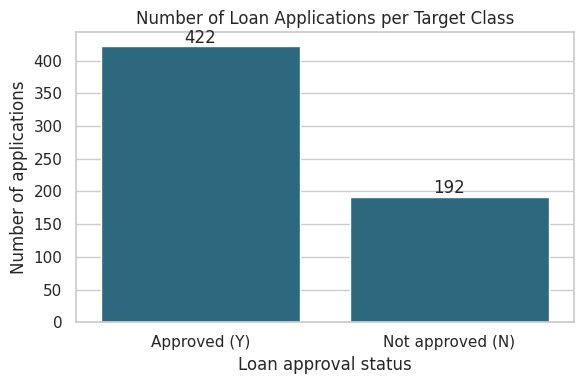

In [5]:
# Is the target balanced?
counts = train_df['Loan_Status'].value_counts()
print(counts.to_dict(), '->', (counts / counts.sum() * 100).round(1).to_dict(), '(%)')

plt.figure(figsize=(6, 4))
sns.countplot(x='Loan_Status', data=train_df, order=['Y', 'N'], color=COLOUR)
plt.xticks([0, 1], ['Approved (Y)', 'Not approved (N)'])
plt.title('Number of Loan Applications per Target Class')
plt.xlabel('Loan approval status')
plt.ylabel('Number of applications')
for i, v in enumerate([counts['Y'], counts['N']]):
    plt.text(i, v + 5, str(v), ha='center')
save_chart('01_target_distribution.png')

About **69% of applications are approved and 31% are not**. The classes are imbalanced but not extremely. Accuracy alone would be misleading later (a model that always says "approved" is right 69% of the time), so this is noted for the modelling stage.

,missing,percent
Credit_History,50,8.1
Self_Employed,32,5.2
LoanAmount,22,3.6
Dependents,15,2.4
Loan_Amount_Term,14,2.3
Gender,13,2.1
Married,3,0.5


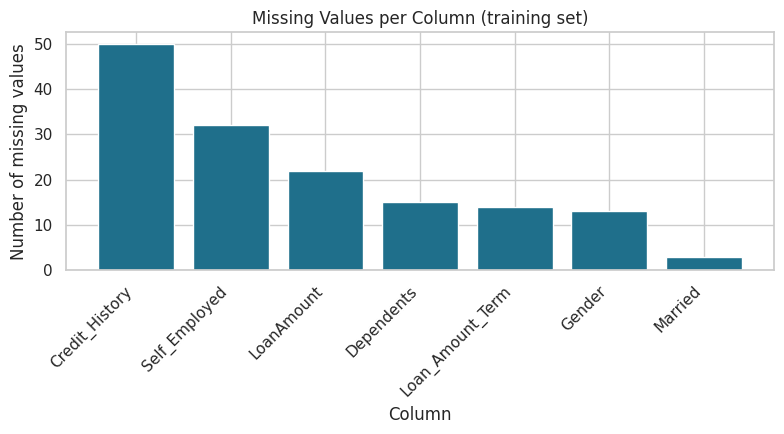

In [6]:
# missing values: how many, and what share of the rows?
missing_table = pd.DataFrame({'missing': train_df.isna().sum(), 'percent': (train_df.isna().mean() * 100).round(1)})
missing_table = missing_table[missing_table['missing'] > 0].sort_values('missing', ascending=False)
display(missing_table)

plt.figure(figsize=(8, 4.5))
plt.bar(missing_table.index, missing_table['missing'], color=COLOUR)
plt.xticks(rotation=45, ha='right')
plt.title('Missing Values per Column (training set)')
plt.xlabel('Column')
plt.ylabel('Number of missing values')
save_chart('02_missing_values.png')

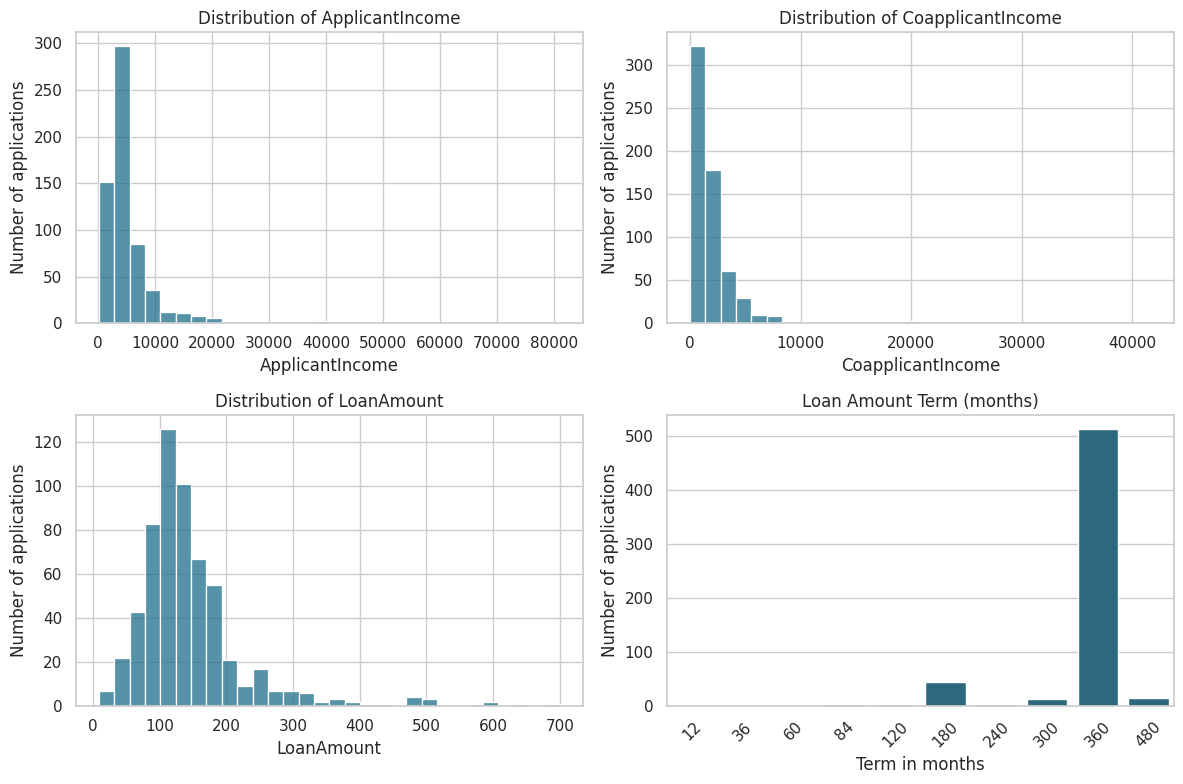

In [7]:
# distributions of the numeric columns
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel()[:3], ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']):
    sns.histplot(train_df[col].dropna(), bins=30, color=COLOUR, ax=ax)
    ax.set_title('Distribution of ' + col)
    ax.set_xlabel(col)
    ax.set_ylabel('Number of applications')
# Loan_Amount_Term has only 10 different values, so a count plot is clearer than a histogram
sns.countplot(x=train_df['Loan_Amount_Term'].dropna().astype(int), color=COLOUR, ax=axes[1, 1])
axes[1, 1].set_title('Loan Amount Term (months)')
axes[1, 1].set_xlabel('Term in months')
axes[1, 1].set_ylabel('Number of applications')
axes[1, 1].tick_params(axis='x', rotation=45)
save_chart('03_numeric_distributions.png')

---
# Part 3 – Feature Engineering & Data Preprocessing
## 3.1 Data cleaning
### Step 1 – Rename columns for clarity
My `rename_columns` function from the original notebook, now applied to **both** the training and the test set.

In [8]:
def rename_columns(df):
    """Give every column a short, clear, lower-case name."""
    return df.rename(columns={'Loan_ID': 'loan_id', 'Gender': 'gender', 'Married': 'married_or_not',
                              'Dependents': 'no_of_dependents', 'Education': 'education_level', 'Self_Employed': 'self_employed_or_not',
                              'ApplicantIncome': 'applicant_income', 'CoapplicantIncome': 'co_applicant_income',
                              'LoanAmount': 'loan_amount', 'Loan_Amount_Term': 'loan_amount_term',
                              'Credit_History': 'credit_history', 'Property_Area': 'property_area', 'Loan_Status': 'loan_status'})

train_df = rename_columns(train_df)
test_df = rename_columns(test_df)       # the test set has no loan_status; rename simply ignores it
print(list(train_df.columns))
print('Same feature columns in train and test:', set(test_df.columns) <= set(train_df.columns))
log_step('3.1 Cleaning', 'Rename columns', 'Renamed all 13 columns to short lower-case names (e.g. ApplicantIncome -> applicant_income)', 'Clear, consistent names are easier to type and read; same names used for train and test')

['loan_id', 'gender', 'married_or_not', 'no_of_dependents', 'education_level', 'self_employed_or_not', 'applicant_income', 'co_applicant_income', 'loan_amount', 'loan_amount_term', 'credit_history', 'property_area', 'loan_status']
Same feature columns in train and test: True


### Step 2 – Duplicate records
**✅ Review note.** The original only *displayed* duplicates (`train_df[train_df.duplicated()]`). The brief asks us to **remove** them where they exist, so the code below checks both fully repeated rows and repeated `loan_id`s and removes any it finds (here, none).

In [9]:
for name, df in [('train', train_df), ('test', test_df)]:
    print(f'{name}: duplicate rows = {df.duplicated().sum()}, repeated loan_id = {df["loan_id"].duplicated().sum()}')

rows_before = len(train_df)
train_df = train_df.drop_duplicates().reset_index(drop=True)
test_df = test_df.drop_duplicates().reset_index(drop=True)
print('Rows removed from train:', rows_before - len(train_df))
log_step('3.1 Cleaning', 'Remove duplicates', 'Checked for repeated rows and repeated loan_id in train and test; none found, so no rows were removed', 'Duplicates would count the same applicant twice and bias a model')

train: duplicate rows = 0, repeated loan_id = 0
test: duplicate rows = 0, repeated loan_id = 0
Rows removed from train: 0


### Step 3 – Missing values
Plan, with the reason for each choice (the **fill values come from the training set only**):

| Column(s) | Type | Method | Reason |
|---|---|---|---|
| gender, married, self-employed, dependents | categories | most common value (**mode**) | A mean makes no sense for categories |
| credit_history, loan_amount_term | yes/no and near-constant numbers | **mode** | credit history is 0 or 1; 83% of terms are 360 months |
| loan_amount | skewed number | **median** | a few very large loans pull the mean upwards; the median is not affected |

First tidy the `3+` value in dependents so it can become a number later.

In [10]:
# '3+' is text. Make it '3' (meaning "three or more") so dependents can be treated as a number
train_df['no_of_dependents'] = train_df['no_of_dependents'].replace('3+', '3')
test_df['no_of_dependents'] = test_df['no_of_dependents'].replace('3+', '3')

mode_cols = ['gender', 'married_or_not', 'self_employed_or_not', 'credit_history', 'loan_amount_term', 'no_of_dependents']

# learn the fill values from TRAIN only
fill_values = {col: train_df[col].mode()[0] for col in mode_cols}
fill_values['loan_amount'] = train_df['loan_amount'].median()
print('Fill values learned from the training set:')
print({k: (v.item() if hasattr(v, 'item') else v) for k, v in fill_values.items()})

missing_before = train_df.isna().sum().sum(), test_df.isna().sum().sum()

# apply the SAME values to train and test
train_df = train_df.fillna(fill_values)
test_df = test_df.fillna(fill_values)

print(f'\nMissing values before: train {missing_before[0]}, test {missing_before[1]}')
print(f'Missing values after:  train {train_df.isna().sum().sum()}, test {test_df.isna().sum().sum()}')
log_step('3.1 Cleaning', 'Handle missing values', 'Filled categories, credit_history, loan_amount_term and dependents with the training-set mode; loan_amount with the training-set median; same values used on the test set', 'Mode suits categories/near-constant columns; median is not distorted by very large loans; using training values avoids leakage')

Fill values learned from the training set:
{'gender': 'Male', 'married_or_not': 'Yes', 'self_employed_or_not': 'No', 'credit_history': 1.0, 'loan_amount_term': 360.0, 'no_of_dependents': '0', 'loan_amount': 128.0}

Missing values before: train 149, test 84
Missing values after:  train 0, test 0


### Step 4 – Correct the data types
After filling the gaps, some columns can be stored as what they really are: whole numbers.

In [11]:
print('Data types BEFORE:')
print(train_df[['no_of_dependents', 'credit_history', 'loan_amount_term', 'applicant_income']].dtypes.to_dict())

for df in (train_df, test_df):
    df['no_of_dependents'] = df['no_of_dependents'].astype(int)       # 0, 1, 2, 3 (3 means 3 or more)
    df['credit_history'] = df['credit_history'].astype(int)           # 0 = no good credit history, 1 = good
    df['loan_amount_term'] = df['loan_amount_term'].astype(int)       # months

print('\nData types AFTER:')
print(train_df.dtypes)
log_step('3.1 Cleaning', 'Correct data types', "no_of_dependents ('3+' -> 3) , credit_history and loan_amount_term converted to whole numbers", 'Each column is stored as what it really is, so it can be used in calculations and encoding')

Data types BEFORE:
{'no_of_dependents': <StringDtype(storage='python', na_value=nan)>, 'credit_history': dtype('float64'), 'loan_amount_term': dtype('float64'), 'applicant_income': dtype('int64')}

Data types AFTER:
loan_id                     str
gender                      str
married_or_not              str
no_of_dependents          int64
education_level             str
self_employed_or_not        str
applicant_income          int64
co_applicant_income     float64
loan_amount             float64
loan_amount_term          int64
credit_history            int64
property_area               str
loan_status                 str
dtype: object


## 3.2 Feature engineering
New columns that describe a household's ability to repay:

| New feature | Formula | Why it helps |
|---|---|---|
| `total_household_income` | applicant + co-applicant income | The bank looks at the income of the whole household |
| `loan_income_ratio` | loan amount ÷ total income | How big the loan is compared with income (higher = riskier) |
| `emi` | loan amount ÷ term (months) | Rough monthly repayment (interest ignored to keep it simple) |
| `balance_income` | total income − emi | Income left after the loan repayment |

**Units:** `loan_amount` is recorded **in thousands**, while incomes are in full amounts. So the loan amount is multiplied by 1,000 before comparing it with income.

In [12]:
def add_features(df):
    """Create the new features (works the same way for train and test)."""
    df = df.copy()
    loan_in_full = df['loan_amount'] * 1000                       # loan_amount is in thousands -> convert to full amount
    df['total_household_income'] = df['applicant_income'] + df['co_applicant_income']
    df['loan_income_ratio'] = loan_in_full / df['total_household_income']
    df['emi'] = loan_in_full / df['loan_amount_term']
    df['balance_income'] = df['total_household_income'] - df['emi']
    return df

train_df = add_features(train_df)
test_df = add_features(test_df)
display(train_df[['applicant_income', 'co_applicant_income', 'loan_amount', 'total_household_income', 'loan_income_ratio', 'emi', 'balance_income']].describe().round(2))
log_step('3.2 Feature engineering', 'Create new features', 'total_household_income, loan_income_ratio, emi, balance_income', 'Describe repayment ability better than the raw columns alone; loan amount multiplied by 1,000 because it is recorded in thousands')

,applicant_income,co_applicant_income,loan_amount,total_household_income,loan_income_ratio,emi,balance_income
count,614.00,614.00,614.00,614.00,614.00,614.00,614.00
mean,5403.46,1621.25,145.75,7024.71,23.88,473.69,6551.02
std,6109.04,2926.25,84.11,6458.66,8.71,511.13,6290.14
min,150.00,0.00,9.00,1442.00,2.52,25.00,-1768.00
25%,2877.50,0.00,100.25,4166.00,19.22,288.89,3804.31
50%,3812.50,1188.50,128.00,5416.50,24.13,361.11,4979.89
75%,5795.00,2297.25,164.75,7521.75,28.16,505.56,6958.03
max,81000.00,41667.00,700.00,81000.00,82.71,9250.00,80000.00


## 3.3 Quick visual exploration (before encoding)
Which categories seem to be linked to approval?

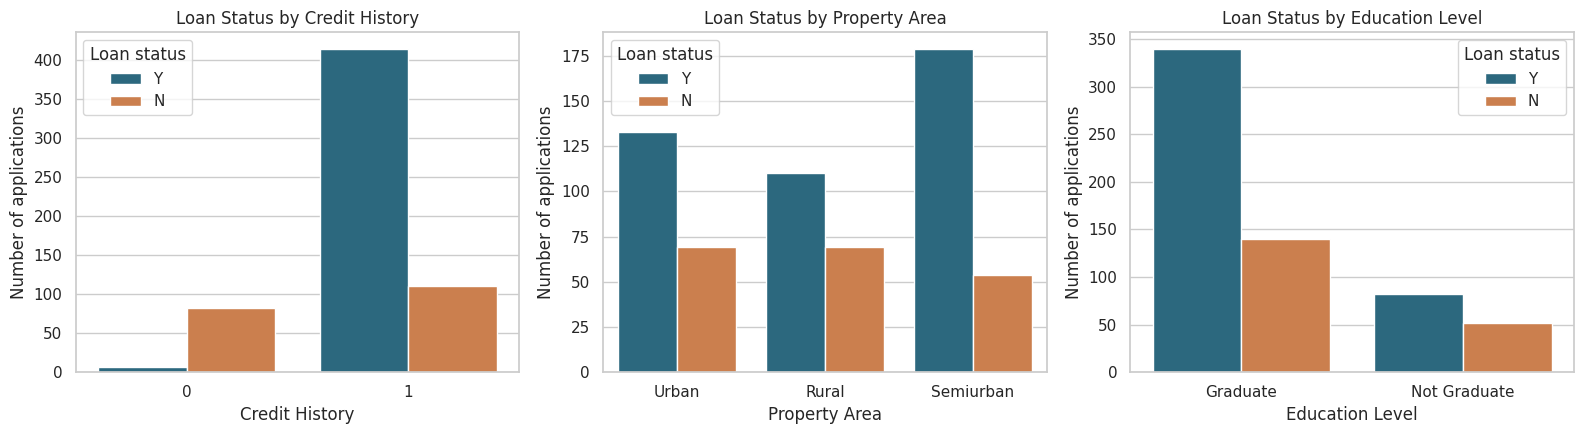

Approval rate by credit_history: {0: 8.0, 1: 79.0}
Approval rate by property_area: {'Rural': 61.0, 'Semiurban': 77.0, 'Urban': 66.0}
Approval rate by education_level: {'Graduate': 71.0, 'Not Graduate': 61.0}
Approval rate by married_or_not: {'No': 63.0, 'Yes': 72.0}
Approval rate by gender: {'Female': 67.0, 'Male': 69.0}
Approval rate by self_employed_or_not: {'No': 69.0, 'Yes': 68.0}


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, title in zip(axes, ['credit_history', 'property_area', 'education_level'], ['Credit History', 'Property Area', 'Education Level']):
    sns.countplot(x=col, hue='loan_status', hue_order=['Y', 'N'], data=train_df, palette=[COLOUR, '#e07b39'], ax=ax)
    ax.set_title('Loan Status by ' + title)
    ax.set_xlabel(title)
    ax.set_ylabel('Number of applications')
    ax.legend(title='Loan status')
save_chart('04_loan_status_by_category.png')

for col in ['credit_history', 'property_area', 'education_level', 'married_or_not', 'gender', 'self_employed_or_not']:
    rate = (train_df['loan_status'] == 'Y').groupby(train_df[col]).mean() * 100
    print(f'Approval rate by {col}:', rate.round(0).to_dict())

**Observation:** `credit_history` is by far the strongest signal: about **80% approved with a good credit history versus about 8% without**. Semi-urban properties and married applicants have somewhat higher approval rates; gender and self-employment make little difference.

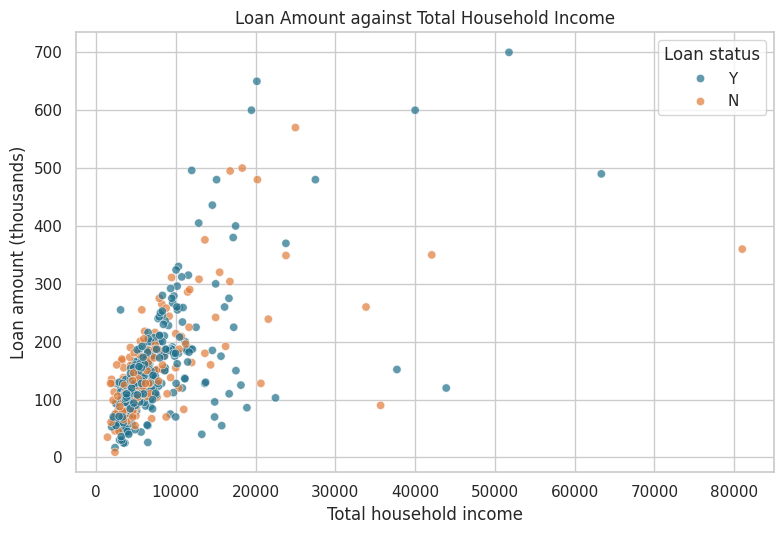

In [14]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(x='total_household_income', y='loan_amount', hue='loan_status', hue_order=['Y', 'N'], palette=[COLOUR, '#e07b39'], data=train_df, alpha=0.7)
plt.title('Loan Amount against Total Household Income')
plt.xlabel('Total household income')
plt.ylabel('Loan amount (thousands)')
plt.legend(title='Loan status')
save_chart('05_income_vs_loan_amount.png')

Larger incomes go with larger loans, but approved and rejected applications are mixed together across the chart, so income and loan amount *alone* do not separate the two groups. The few points far to the right are the outliers handled next.

## 3.4 Save the cleaned dataset
The cleaned dataset has had duplicates removed, gaps filled, data types corrected and new features added, but it is **not yet encoded, capped or scaled**, so it stays readable for people.

In [15]:
train_df.to_csv('Cleaned_Data/train_cleaned.csv', index=False)
test_df.to_csv('Cleaned_Data/test_cleaned.csv', index=False)
print('Saved cleaned train:', train_df.shape, '| cleaned test:', test_df.shape)
print('Missing values in cleaned data: train', train_df.isna().sum().sum(), '| test', test_df.isna().sum().sum())

Saved cleaned train: (614, 17) | cleaned test: (367, 16)
Missing values in cleaned data: train 0 | test 0


## 3.5 Feature encoding
Machine learning models need numbers. Which technique for which column?

| Column | Type | Technique | Why |
|---|---|---|---|
| gender, married_or_not, education_level, self_employed_or_not | 2 categories | **Label (binary) encoding** 0/1 | With only two values, one 0/1 column holds all the information |
| loan_status (target) | 2 categories | **Label encoding** Y=1, N=0 | The model predicts 1 = approved |
| no_of_dependents | ordered number 0–3 | kept as a **number** | 3 dependents really is more than 1; one-hot would throw away this order |
| property_area | 3 categories, **no order** | **One-hot encoding** | Label encoding Rural=0, Semiurban=1, Urban=2 would falsely say Urban is "twice" Semiurban |

For one-hot encoding I use `drop_first=True`: with 3 areas, two columns are enough (Rural is when both are 0). Keeping all three would make one column perfectly predictable from the other two (redundant).

In [16]:
ml_train_df = train_df.copy()
ml_test_df = test_df.copy()

binary_maps = {'gender': {'Male': 1, 'Female': 0}, 'married_or_not': {'Yes': 1, 'No': 0},
               'education_level': {'Graduate': 1, 'Not Graduate': 0}, 'self_employed_or_not': {'Yes': 1, 'No': 0}}

def encode_features(df):
    """Binary-encode the 2-category columns and one-hot encode property_area."""
    df = df.copy()
    for col, mapping in binary_maps.items():
        df[col] = df[col].map(mapping)
    df = pd.get_dummies(df, columns=['property_area'], drop_first=True, dtype=int)
    return df

ml_train_df = encode_features(ml_train_df)
ml_test_df = encode_features(ml_test_df)
ml_train_df['loan_status'] = ml_train_df['loan_status'].map({'Y': 1, 'N': 0})

# the test set must have exactly the same columns, in the same order, as the training features
feature_columns = [c for c in ml_train_df.columns if c not in ('loan_id', 'loan_status')]
ml_test_df = ml_test_df.reindex(columns=['loan_id'] + feature_columns, fill_value=0)

# safety check: an unexpected spelling would have become NaN
assert ml_train_df[feature_columns + ['loan_status']].isna().sum().sum() == 0
assert ml_test_df[feature_columns].isna().sum().sum() == 0
print('Encoded columns:', feature_columns)
display(ml_train_df.head())
log_step('3.3 Encoding', 'Label encoding', 'gender, married_or_not, education_level, self_employed_or_not and the target loan_status mapped to 0/1', 'Two-category columns need only one 0/1 column')
log_step('3.3 Encoding', 'Keep ordered number', 'no_of_dependents kept as the numbers 0-3', 'It has a natural order, which one-hot encoding would lose')
log_step('3.3 Encoding', 'One-hot encoding', 'property_area -> property_area_Semiurban and property_area_Urban (Rural = both 0); drop_first=True', 'Three unordered categories; dropping one column avoids a redundant column')

Encoded columns: ['gender', 'married_or_not', 'no_of_dependents', 'education_level', 'self_employed_or_not', 'applicant_income', 'co_applicant_income', 'loan_amount', 'loan_amount_term', 'credit_history', 'total_household_income', 'loan_income_ratio', 'emi', 'balance_income', 'property_area_Semiurban', 'property_area_Urban']


,loan_id,gender,married_or_not,no_of_dependents,education_level,self_employed_or_not,applicant_income,co_applicant_income,loan_amount,loan_amount_term,credit_history,loan_status,total_household_income,loan_income_ratio,emi,balance_income,property_area_Semiurban,property_area_Urban
0,LP001002,1,0,0,1,0,5849,0.0,128.0,360,1,1,5849.0,21.884083,355.555556,5493.444444,0,1
1,LP001003,1,1,1,1,0,4583,1508.0,128.0,360,1,0,6091.0,21.014612,355.555556,5735.444444,0,0
2,LP001005,1,1,0,1,1,3000,0.0,66.0,360,1,1,3000.0,22.000000,183.333333,2816.666667,0,1
3,LP001006,1,1,0,0,0,2583,2358.0,120.0,360,1,1,4941.0,24.286582,333.333333,4607.666667,0,1
4,LP001008,1,0,0,1,0,6000,0.0,141.0,360,1,1,6000.0,23.500000,391.666667,5608.333333,0,1


## 3.6 Outlier detection and treatment
**Step 1 – look (box plots).** Points beyond the whiskers are potential outliers.

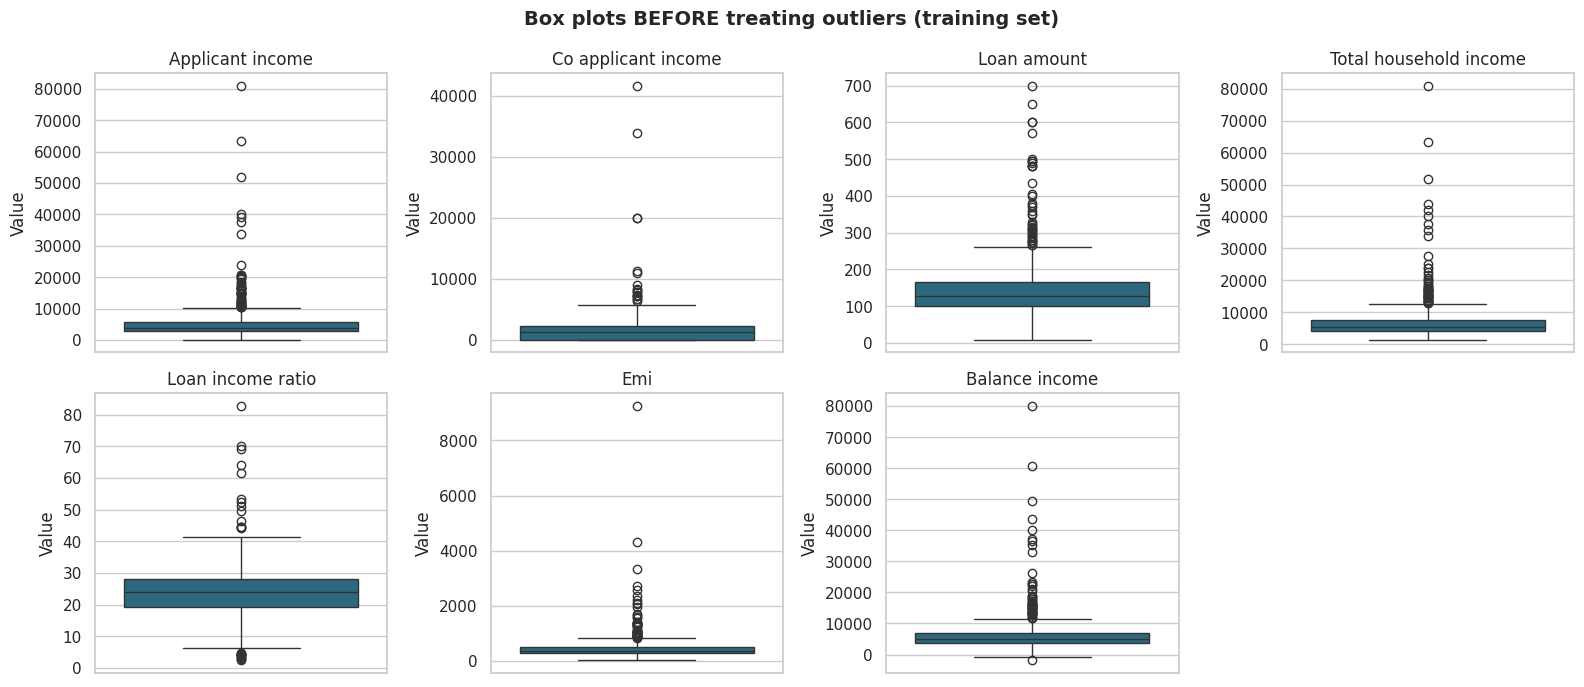

In [17]:
outlier_cols = ['applicant_income', 'co_applicant_income', 'loan_amount', 'total_household_income', 'loan_income_ratio', 'emi', 'balance_income']

def plot_boxplots(df, title, filename):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, col in zip(axes.ravel(), outlier_cols):
        sns.boxplot(y=df[col], color=COLOUR, ax=ax)
        ax.set_title(col.replace('_', ' ').capitalize())
        ax.set_ylabel('Value')
    axes.ravel()[-1].axis('off')
    fig.suptitle(title, fontsize=14, fontweight='bold')
    save_chart(filename)

plot_boxplots(ml_train_df, 'Box plots BEFORE treating outliers (training set)', '06_boxplots_before_capping.png')

**Step 2 – count them.** The **IQR method**: Q1 and Q3 are the 25th and 75th percentiles, IQR = Q3 − Q1. Anything below Q1 − 1.5×IQR or above Q3 + 1.5×IQR is flagged. For comparison the **z-score method** flags values more than 3 standard deviations from the mean.

In [18]:
limits = {}                    # outlier limits learned from the TRAINING set only
rows = []
for col in outlier_cols:
    q1, q3 = ml_train_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    limits[col] = (lower, upper)
    z = (ml_train_df[col] - ml_train_df[col].mean()) / ml_train_df[col].std()
    rows.append((col, round(lower, 2), round(upper, 2), int(((ml_train_df[col] < lower) | (ml_train_df[col] > upper)).sum()), int((z.abs() > 3).sum()), round(ml_train_df[col].max(), 2)))
outlier_table = pd.DataFrame(rows, columns=['column', 'lower_limit', 'upper_limit', 'iqr_outliers', 'zscore_outliers', 'max_value']).set_index('column')
display(outlier_table)

,lower_limit,upper_limit,iqr_outliers,zscore_outliers,max_value
column,,,,,
applicant_income,-1498.75,10171.25,50,8,81000.00
co_applicant_income,-3445.88,5743.12,18,6,41667.00
loan_amount,3.50,261.50,41,15,700.00
total_household_income,-867.62,12555.38,50,10,81000.00
loan_income_ratio,5.81,41.56,25,8,82.71
emi,-36.11,830.56,50,9,9250.00
balance_income,-926.28,11688.61,52,10,80000.00


**Step 3 – decide.** I **cap** (winsorise) instead of deleting rows: values above the upper limit are set to the upper limit (and below the lower limit to the lower limit).
* With only 614 rows, deleting 50–100 would throw away a lot of information.
* Very high incomes are probably *real* (a few high earners), not data-entry errors, so the rows are valid. Capping keeps the row but stops one extreme value from dominating the model.
* The limits come from the training set and are applied to the test set too.

The IQR method flags more values than the z-score method because the data is so skewed (a few huge values inflate the standard deviation, so z-scores hide them). That is why IQR was chosen.

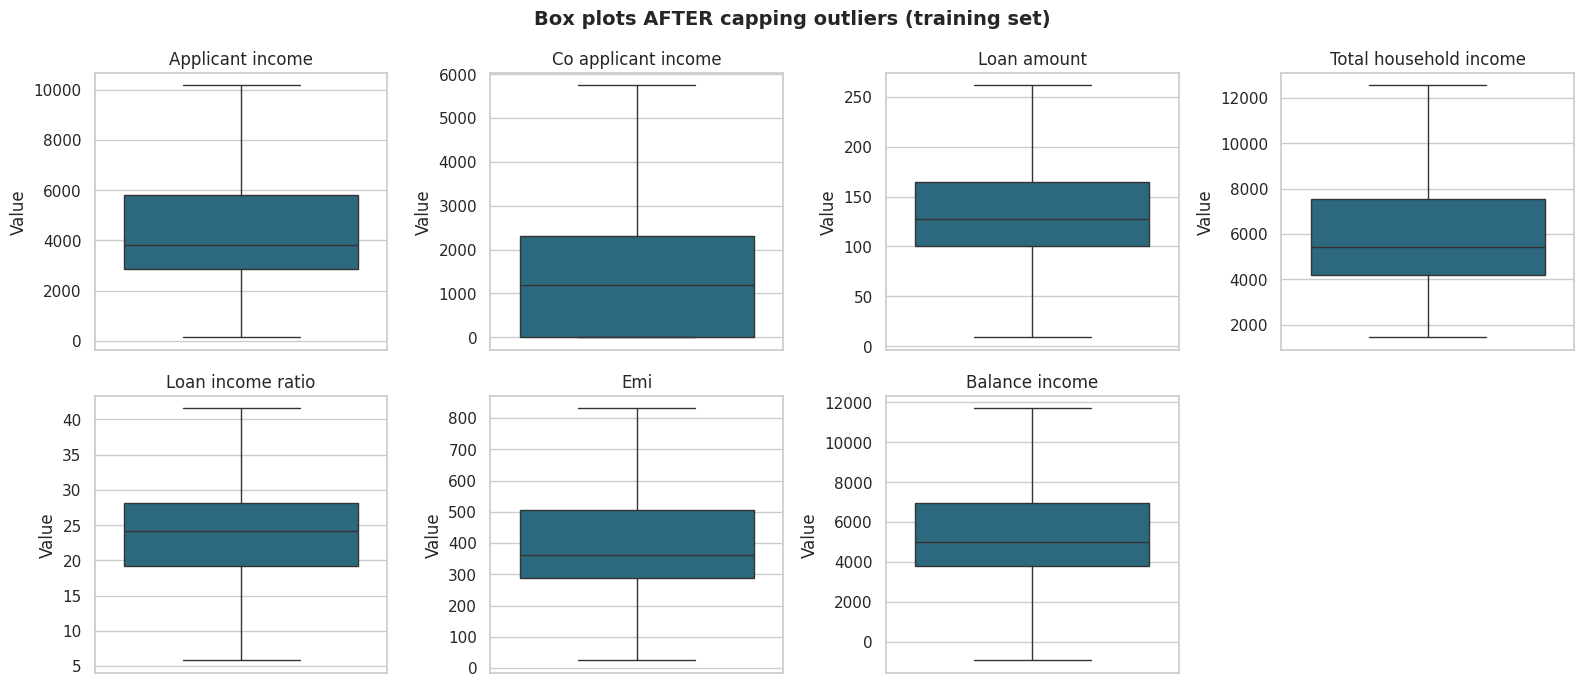

Largest applicant income after capping: 10171 (was 81,000)


In [19]:
for col, (lower, upper) in limits.items():
    ml_train_df[col] = ml_train_df[col].clip(lower, upper)
    ml_test_df[col] = ml_test_df[col].clip(lower, upper)      # same limits for the test set

plot_boxplots(ml_train_df, 'Box plots AFTER capping outliers (training set)', '07_boxplots_after_capping.png')
print('Largest applicant income after capping:', round(ml_train_df['applicant_income'].max()), '(was 81,000)')
log_step('3.5 Outliers', 'Detect outliers', 'Box plots and the IQR rule (1.5 x IQR) on 7 numeric columns; z-score (|z| > 3) used as a comparison', 'IQR is better for skewed data because extreme values do not distort it')
log_step('3.5 Outliers', 'Cap outliers', 'Values outside the IQR limits set to the limit (limits learned on train, applied to train and test)', 'Keeps all rows (only 614) while limiting the influence of extreme values that are probably genuine')

## 3.7 Feature scaling
The numeric columns are on very different scales (income in thousands, loan term in hundreds, ratios in tens). Models that use distances or gradients (logistic regression, KNN, neural networks) would let the biggest numbers dominate.

**Choice: `StandardScaler`** (subtract the mean, divide by the standard deviation, so each column has mean 0 and standard deviation 1).
* After capping, the extreme values that would distort a mean-based scaler are gone, so StandardScaler is safe. (If outliers had been left in, `RobustScaler` would be the better choice.)
* Only the **continuous** columns are scaled. The 0/1 columns and the 0–3 dependents count already have small, meaningful scales.
* The scaler is **fitted on the training set** and only *applies* the same transformation to the test set.

BEFORE scaling:


,applicant_income,co_applicant_income,loan_amount,total_household_income,loan_income_ratio,emi,balance_income,loan_amount_term
mean,4617.11,1419.70,137.37,6194.72,23.59,414.87,5726.33,342.41
std,2479.85,1624.61,55.78,2875.79,7.45,189.90,2737.27,64.43
min,150.00,0.00,9.00,1442.00,5.81,25.00,-926.28,12.00
max,10171.25,5743.12,261.50,12555.38,41.56,830.56,11688.61,480.00


AFTER scaling (training set):


,applicant_income,co_applicant_income,loan_amount,total_household_income,loan_income_ratio,emi,balance_income,loan_amount_term
mean,0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.80,-0.87,-2.30,-1.65,-2.39,-2.05,-2.43,-5.13
max,2.24,2.66,2.23,2.21,2.41,2.19,2.18,2.14


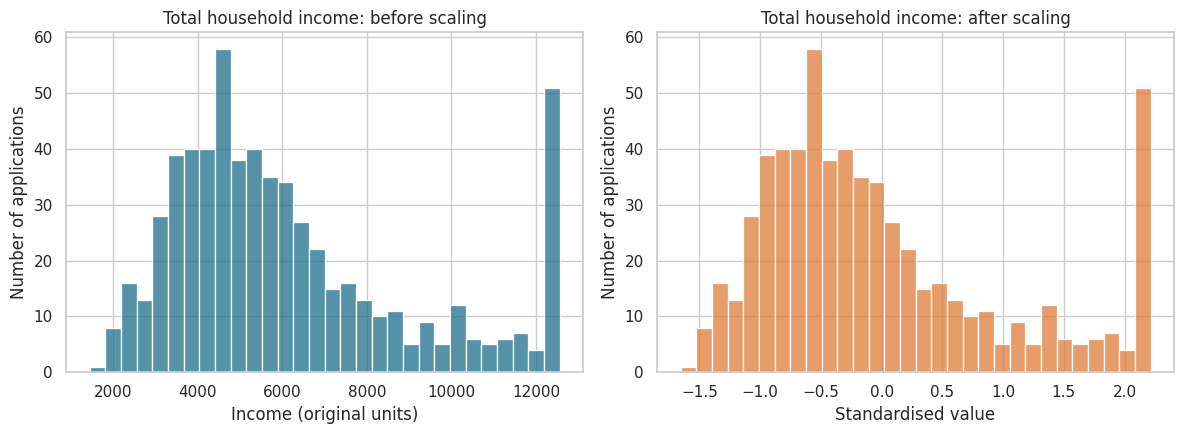

In [20]:
scale_cols = outlier_cols + ['loan_amount_term']
scaler = StandardScaler()

before = ml_train_df[scale_cols].describe().loc[['mean', 'std', 'min', 'max']].round(2)
ml_train_df[scale_cols] = scaler.fit_transform(ml_train_df[scale_cols])      # learn mean/std from train, then transform
ml_test_df[scale_cols] = scaler.transform(ml_test_df[scale_cols])            # reuse the training mean/std (no refitting)

print('BEFORE scaling:'); display(before)
print('AFTER scaling (training set):'); display(ml_train_df[scale_cols].describe().loc[['mean', 'std', 'min', 'max']].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
capped_income = train_df['total_household_income'].clip(*limits['total_household_income'])      # capped but NOT yet scaled
sns.histplot(capped_income, bins=30, color=COLOUR, ax=axes[0])
axes[0].set_title('Total household income: before scaling')
axes[0].set_xlabel('Income (original units)')
axes[0].set_ylabel('Number of applications')
sns.histplot(ml_train_df['total_household_income'], bins=30, color='#e07b39', ax=axes[1])
axes[1].set_title('Total household income: after scaling')
axes[1].set_xlabel('Standardised value')
axes[1].set_ylabel('Number of applications')
save_chart('08_scaling_before_after.png')
log_step('3.6 Scaling', 'StandardScaler', '8 continuous columns (incomes, loan amount, ratios, emi, balance income, loan term) standardised; scaler fitted on train and reused on test', 'Puts all columns on the same scale for distance/gradient-based models; safe after capping; 0/1 columns left unscaled')

The *shape* of the distribution is unchanged; only the units are (the horizontal axis changes from naira-type amounts to standard deviations from the average).
**✅ Review note.** The original notebook imported `StandardScaler` but never used it: scaling was missing entirely, although the brief requires it.

---
# Part 4 – Feature Selection
Goal: decide which features to **keep** and which to **remove**, using evidence. Three tools:
1. a **correlation heatmap** (which features move together?),
2. **correlation with the target** (which features move with loan approval?),
3. **feature importance** from a Random Forest (a second opinion that can also see non-linear patterns).

*(The Random Forest is used only to rank the features. It is not the final model.)*

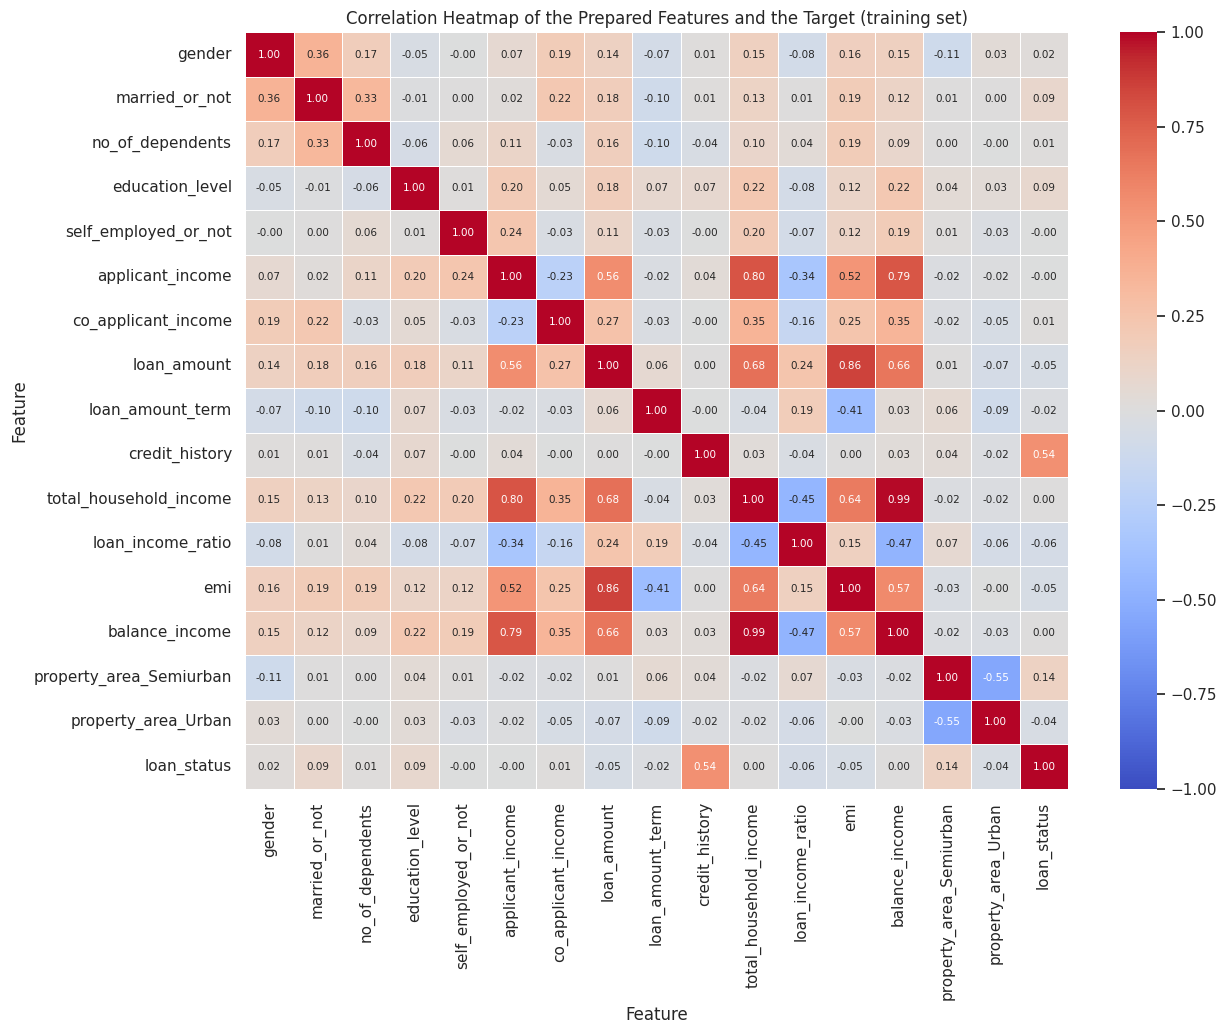

In [21]:
corr = ml_train_df[feature_columns + ['loan_status']].corr()

plt.figure(figsize=(13, 10.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size': 7.5}, linewidths=0.4)
plt.title('Correlation Heatmap of the Prepared Features and the Target (training set)')
plt.xlabel('Feature')
plt.ylabel('Feature')
save_chart('09_correlation_heatmap.png')

### 4.1 Highly correlated (redundant) features
Two features that are almost copies of each other add little new information (and can confuse linear models). Rule used: look at pairs with a correlation of **0.8 or more** (positive or negative).

In [22]:
upper_triangle = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))      # each pair once
pairs = upper_triangle.stack().reset_index()
pairs.columns = ['feature_1', 'feature_2', 'correlation']
pairs['abs_correlation'] = pairs['correlation'].abs()
pairs = pairs.sort_values('abs_correlation', ascending=False)

print('Pairs with |correlation| of 0.8 or more:')
high_pairs = pairs[(pairs['abs_correlation'] >= 0.8) & (pairs['feature_1'] != 'loan_status') & (pairs['feature_2'] != 'loan_status')]
display(high_pairs.round(3))
print('Next strongest pairs (for information):')
display(pairs[(pairs['abs_correlation'] < 0.8)].head(5).round(3))

Pairs with |correlation| of 0.8 or more:


,feature_1,feature_2,correlation,abs_correlation
183,total_household_income,balance_income,0.989,0.989
131,loan_amount,emi,0.858,0.858


Next strongest pairs (for information):


,feature_1,feature_2,correlation,abs_correlation
95,applicant_income,total_household_income,0.796,0.796
98,applicant_income,balance_income,0.788,0.788
129,loan_amount,total_household_income,0.685,0.685
132,loan_amount,balance_income,0.660,0.660
182,total_household_income,emi,0.636,0.636


* `total_household_income` and `balance_income` are almost identical (balance income is total income minus a small repayment), so **`balance_income` is redundant**.
* `loan_amount` and `emi` are strongly related (`emi` is the loan amount divided by the term, and 83% of terms are 360 months), so **`emi` is redundant**; the relationship between loan and income is already held by `loan_income_ratio`.
* `applicant_income` and `total_household_income` are just under the 0.8 limit. Total income is built from applicant + co-applicant income, so they overlap *by design*, but I keep them for now (tree models are not bothered by this).

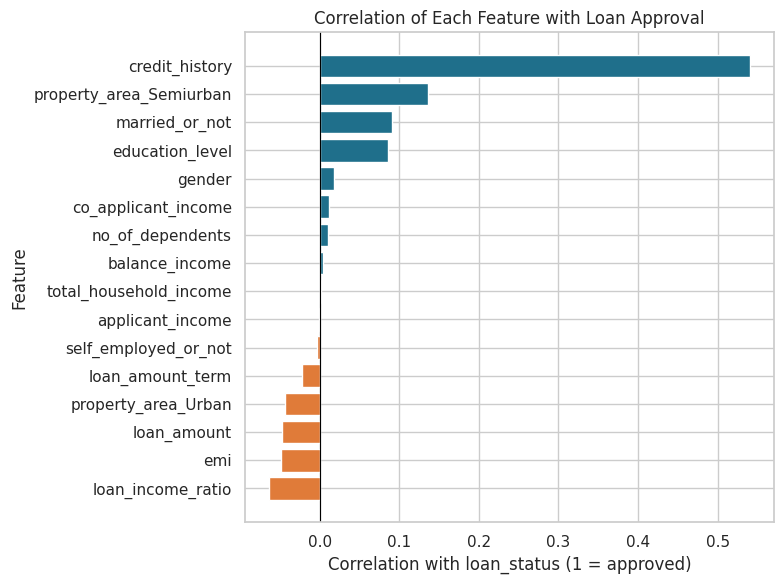

In [23]:
# correlation of each feature with the target
target_corr = corr['loan_status'].drop('loan_status').sort_values()

plt.figure(figsize=(8, 6))
plt.barh(target_corr.index, target_corr.values, color=[COLOUR if v >= 0 else '#e07b39' for v in target_corr.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of Each Feature with Loan Approval')
plt.xlabel('Correlation with loan_status (1 = approved)')
plt.ylabel('Feature')
save_chart('10_correlation_with_target.png')

### 4.2 Feature importance (Random Forest)

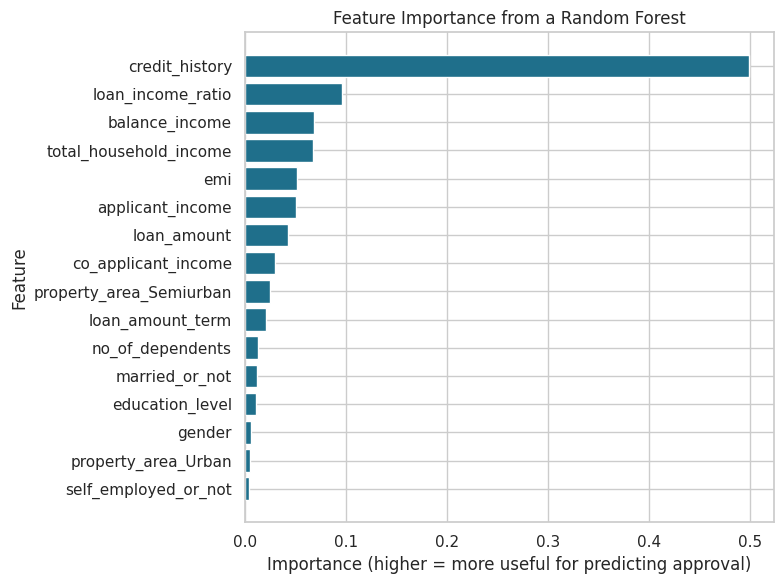

,importance
credit_history,0.499
loan_income_ratio,0.096
balance_income,0.069
total_household_income,0.068
emi,0.051
applicant_income,0.050
loan_amount,0.043
co_applicant_income,0.029


In [24]:
forest = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42)       # small, simple forest (random_state makes it repeatable)
forest.fit(ml_train_df[feature_columns], ml_train_df['loan_status'])
importance = pd.Series(forest.feature_importances_, index=feature_columns).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importance.index, importance.values, color=COLOUR)
plt.title('Feature Importance from a Random Forest')
plt.xlabel('Importance (higher = more useful for predicting approval)')
plt.ylabel('Feature')
save_chart('11_feature_importance.png')
display(importance.sort_values(ascending=False).round(3).to_frame('importance').head(8))

**Most important features:** `credit_history` stands far above everything else (correlation about 0.54 with approval and about half of the total importance). Next come `loan_income_ratio` and the income and loan-amount features, each with a small share.
Everything else (education, marital status, dependents, loan term, property area) has a small effect, and gender and self-employment have almost none.

### 4.3 Decisions: which features to remove
Only features with a clear reason are removed. With just 614 rows and a mix of linear and non-linear effects, I do **not** remove a feature only because it is weak on its own.

In [25]:
feature_decisions = pd.DataFrame([
    ('loan_id', 'REMOVE', 'An identifier. It is unique for every application, so it carries no pattern a model can learn (already left out of the model features).'),
    ('balance_income', 'REMOVE', f"Redundant: correlation {corr.loc['total_household_income', 'balance_income']:.2f} with total_household_income."),
    ('emi', 'REMOVE', f"Redundant: correlation {corr.loc['loan_amount', 'emi']:.2f} with loan_amount; loan_income_ratio already captures loan size against income."),
    ('gender', 'REMOVE', f"Almost no relationship with approval (correlation {corr.loc['gender', 'loan_status']:.2f}, importance {importance['gender']:.3f}), and it is a sensitive personal attribute that lenders should not rely on in credit decisions."),
    ('credit_history', 'KEEP', f"Strongest feature (correlation {corr.loc['credit_history', 'loan_status']:.2f}, importance {importance['credit_history']:.2f})."),
    ('loan_income_ratio', 'KEEP', 'Second most important feature (engineered).'),
    ('total_household_income, applicant_income, co_applicant_income, loan_amount', 'KEEP', 'Core financial features; overlap between them is moderate (below 0.8).'),
    ('married_or_not, education_level, no_of_dependents, loan_amount_term, property_area_*, self_employed_or_not', 'KEEP', 'Weak on their own but not redundant; small data, so they are kept for the model to judge.'),
], columns=['feature', 'decision', 'reason'])
with pd.option_context('display.max_colwidth', 160):
    display(feature_decisions)

drop_features = ['balance_income', 'emi', 'gender']
log_step('4 Feature selection', 'Remove identifier', 'loan_id excluded from the model features', 'Unique per row; no predictive pattern')
log_step('4 Feature selection', 'Remove redundant features', 'balance_income (r=0.99 with total_household_income) and emi (r=0.86 with loan_amount) removed', 'Highly correlated pairs (|r| >= 0.8) repeat the same information')
log_step('4 Feature selection', 'Remove gender', 'gender removed', 'No relationship with approval and a sensitive attribute that should not drive credit decisions')

,feature,decision,reason
0,loan_id,REMOVE,"An identifier. It is unique for every application, so it carries no pattern a model can learn (already left out of the model features)."
1,balance_income,REMOVE,Redundant: correlation 0.99 with total_household_income.
2,emi,REMOVE,Redundant: correlation 0.86 with loan_amount; loan_income_ratio already captures loan size against income.
3,gender,REMOVE,"Almost no relationship with approval (correlation 0.02, importance 0.006), and it is a sensitive personal attribute that lenders should not rely on in credi..."
4,credit_history,KEEP,"Strongest feature (correlation 0.54, importance 0.50)."
5,loan_income_ratio,KEEP,Second most important feature (engineered).
6,"total_household_income, applicant_income, co_applicant_income, loan_amount",KEEP,Core financial features; overlap between them is moderate (below 0.8).
7,"married_or_not, education_level, no_of_dependents, loan_amount_term, property_area_*, self_employed_or_not",KEEP,"Weak on their own but not redundant; small data, so they are kept for the model to judge."


**✅ Review note – feature selection.** The original notebook had no correlation heatmap, no look at redundant features and no feature importance, which together are 15% of the marks (Feature Selection). The decisions above are each backed by a number from the charts.

---
# Part 5 – Final Machine Learning Dataset

In [26]:
final_features = [c for c in feature_columns if c not in drop_features]

ml_ready_train = ml_train_df[final_features + ['loan_status']].copy()
ml_ready_test = ml_test_df[final_features].copy()            # the test set has no target column

print('Final features (', len(final_features), '):', final_features)
print('ML-ready train:', ml_ready_train.shape, '| ML-ready test:', ml_ready_test.shape)

# ---- safety checks: is the data really ready? ----
assert ml_ready_train.isna().sum().sum() == 0 and ml_ready_test.isna().sum().sum() == 0, 'missing values remain'
assert all(pd.api.types.is_numeric_dtype(t) for t in ml_ready_train.dtypes), 'a non-numeric column remains'
assert list(ml_ready_test.columns) == final_features, 'train and test columns differ'
assert set(ml_ready_train['loan_status'].unique()) == {0, 1}, 'target is not 0/1'
print('All checks passed: no missing values, all columns numeric, train and test have the same features, target is 0/1.')
display(ml_ready_train.head())
display(ml_ready_train.describe().round(2).T[['mean', 'std', 'min', 'max']])

Final features ( 13 ): ['married_or_not', 'no_of_dependents', 'education_level', 'self_employed_or_not', 'applicant_income', 'co_applicant_income', 'loan_amount', 'loan_amount_term', 'credit_history', 'total_household_income', 'loan_income_ratio', 'property_area_Semiurban', 'property_area_Urban']
ML-ready train: (614, 14) | ML-ready test: (367, 13)
All checks passed: no missing values, all columns numeric, train and test have the same features, target is 0/1.


,married_or_not,no_of_dependents,education_level,self_employed_or_not,applicant_income,co_applicant_income,loan_amount,loan_amount_term,credit_history,total_household_income,loan_income_ratio,property_area_Semiurban,property_area_Urban,loan_status
0,0,0,1,0,0.497164,-0.874587,-0.168041,0.273231,1,-0.120316,-0.229720,0,1,1
1,1,1,1,0,-0.013767,0.054395,-0.168041,0.273231,1,-0.036097,-0.346531,0,0,0
2,1,0,1,1,-0.652632,-0.874587,-1.280462,0.273231,1,-1.111808,-0.214147,0,1,1
3,1,0,0,0,-0.820924,0.578025,-0.311579,0.273231,1,-0.436313,0.093049,0,1,1
4,0,0,1,0,0.558104,-0.874587,0.065209,0.273231,1,-0.067766,-0.012626,0,1,1


,mean,std,min,max
married_or_not,0.65,0.48,0.00,1.00
no_of_dependents,0.74,1.01,0.00,3.00
education_level,0.78,0.41,0.00,1.00
self_employed_or_not,0.13,0.34,0.00,1.00
applicant_income,0.00,1.00,-1.80,2.24
co_applicant_income,0.00,1.00,-0.87,2.66
loan_amount,0.00,1.00,-2.30,2.23
loan_amount_term,0.00,1.00,-5.13,2.14
credit_history,0.86,0.35,0.00,1.00
total_household_income,0.00,1.00,-1.65,2.21


In [27]:
# save the deliverables
ml_ready_train.to_csv('ML_Ready_Data/ml_ready_train.csv', index=False)
ml_ready_test.to_csv('ML_Ready_Data/ml_ready_test.csv', index=False)
test_df[['loan_id']].to_csv('ML_Ready_Data/test_loan_ids.csv', index=False)         # the test rows are in the same order, so predictions can be matched back to applicants

log_step('5 Final dataset', 'Build and check final dataset', f'{len(final_features)} features + target (train), {len(final_features)} features (test); checks for missing values, numeric types and matching columns passed', 'Confirms the data can be given directly to a model')
preprocessing_log_df = pd.DataFrame(preprocessing_log)
preprocessing_log_df.insert(0, 'no', range(1, len(preprocessing_log_df) + 1))
preprocessing_log_df.to_csv('Cleaned_Data/Preprocessing_Log.csv', index=False)
with pd.option_context('display.max_colwidth', 150):
    display(preprocessing_log_df)
print('Saved: ML_Ready_Data/ml_ready_train.csv, ml_ready_test.csv, test_loan_ids.csv and Cleaned_Data/Preprocessing_Log.csv')

,no,part,step,what_was_done,why
0,1,3.1 Cleaning,Rename columns,Renamed all 13 columns to short lower-case names (e.g. ApplicantIncome -> applicant_income),"Clear, consistent names are easier to type and read; same names used for train and test"
1,2,3.1 Cleaning,Remove duplicates,"Checked for repeated rows and repeated loan_id in train and test; none found, so no rows were removed",Duplicates would count the same applicant twice and bias a model
2,3,3.1 Cleaning,Handle missing values,"Filled categories, credit_history, loan_amount_term and dependents with the training-set mode; loan_amount with the training-set median; same valu...",Mode suits categories/near-constant columns; median is not distorted by very large loans; using training values avoids leakage
3,4,3.1 Cleaning,Correct data types,"no_of_dependents ('3+' -> 3) , credit_history and loan_amount_term converted to whole numbers","Each column is stored as what it really is, so it can be used in calculations and encoding"
4,5,3.2 Feature engineering,Create new features,"total_household_income, loan_income_ratio, emi, balance_income","Describe repayment ability better than the raw columns alone; loan amount multiplied by 1,000 because it is recorded in thousands"
5,6,3.3 Encoding,Label encoding,"gender, married_or_not, education_level, self_employed_or_not and the target loan_status mapped to 0/1",Two-category columns need only one 0/1 column
6,7,3.3 Encoding,Keep ordered number,no_of_dependents kept as the numbers 0-3,"It has a natural order, which one-hot encoding would lose"
7,8,3.3 Encoding,One-hot encoding,property_area -> property_area_Semiurban and property_area_Urban (Rural = both 0); drop_first=True,Three unordered categories; dropping one column avoids a redundant column
8,9,3.5 Outliers,Detect outliers,Box plots and the IQR rule (1.5 x IQR) on 7 numeric columns; z-score (|z| > 3) used as a comparison,IQR is better for skewed data because extreme values do not distort it
9,10,3.5 Outliers,Cap outliers,"Values outside the IQR limits set to the limit (limits learned on train, applied to train and test)",Keeps all rows (only 614) while limiting the influence of extreme values that are probably genuine


Saved: ML_Ready_Data/ml_ready_train.csv, ml_ready_test.csv, test_loan_ids.csv and Cleaned_Data/Preprocessing_Log.csv


The table above is the **explanation of every preprocessing step** (what was done and why), ready to be reused in the Data Preprocessing Report.

## Answers to the business questions

In [28]:
n_missing_train = int(missing_before[0])
print('1. Which features are most relevant?')
print(f"   credit_history by a wide margin (correlation {corr.loc['credit_history', 'loan_status']:.2f}, ~{importance['credit_history'] * 100:.0f}% of importance). Next: loan_income_ratio and the income / loan-amount features. Gender, self-employment and dependents are almost irrelevant.\n")
print('2. Which variables require encoding?')
print('   gender, married_or_not, education_level, self_employed_or_not and loan_status -> 0/1 (label encoding); property_area -> one-hot encoding; no_of_dependents is already an ordered number (3+ became 3).\n')
print('3. Which variables require scaling?')
kept_scaled = [c for c in scale_cols if c in final_features]
print(f"   The continuous columns were standardised ({len(scale_cols)} in total; {len(kept_scaled)} remain after feature selection: {', '.join(kept_scaled)}). The 0/1 columns and dependents were left as they are. Tree-based models would not need scaling; logistic regression and KNN do.\n")
print('4. Redundant or highly correlated features?')
print(f"   balance_income vs total_household_income (r = {corr.loc['total_household_income', 'balance_income']:.2f}) and emi vs loan_amount (r = {corr.loc['loan_amount', 'emi']:.2f}) -> both engineered features removed. applicant_income and total_household_income overlap moderately (r = {corr.loc['applicant_income', 'total_household_income']:.2f}).\n")
print('5. How were missing values and outliers handled?')
print(f"   {n_missing_train} missing cells in the training set (7 columns) were filled with the training mode (categories, credit history, term, dependents) or median (loan amount); the same values were used on the test set. "
      f"Outliers (IQR rule: {int(outlier_table.loc['applicant_income', 'iqr_outliers'])} in applicant income, {int(outlier_table.loc['co_applicant_income', 'iqr_outliers'])} in co-applicant income, {int(outlier_table.loc['loan_amount', 'iqr_outliers'])} in loan amount) were capped at the IQR limits, not deleted.\n")
print('6. Which techniques improved the dataset quality?')
print('   Filling gaps, correcting data types, encoding, capping outliers, scaling, creating household/repayment features (loan_income_ratio was the second most important feature) and removing redundant features.\n')
print('7. Is the dataset ready for machine learning?')
print(f"   Yes. The final training set has {ml_ready_train.shape[0]} rows, {len(final_features)} numeric features and a 0/1 target, with no missing values; the test set has the same features. "
      'Points to remember at the modelling stage: the data is small (614 rows), the target is imbalanced (69% approved), credit_history dominates, and the test set has no answers, so use a validation split of the training data to measure performance.')

n_charts = len([f for f in os.listdir('Visualizations') if f.endswith('.png')])
print(f'\nVisualisations saved: {n_charts} (the brief requires at least 6)')

1. Which features are most relevant?
   credit_history by a wide margin (correlation 0.54, ~50% of importance). Next: loan_income_ratio and the income / loan-amount features. Gender, self-employment and dependents are almost irrelevant.

2. Which variables require encoding?
   gender, married_or_not, education_level, self_employed_or_not and loan_status -> 0/1 (label encoding); property_area -> one-hot encoding; no_of_dependents is already an ordered number (3+ became 3).

3. Which variables require scaling?
   The continuous columns were standardised (8 in total; 6 remain after feature selection: applicant_income, co_applicant_income, loan_amount, total_household_income, loan_income_ratio, loan_amount_term). The 0/1 columns and dependents were left as they are. Tree-based models would not need scaling; logistic regression and KNN do.

4. Redundant or highly correlated features?
   balance_income vs total_household_income (r = 0.99) and emi vs loan_amount (r = 0.86) -> both engineered 